# 【保留】発効後のグループ比較（2025年10月以降）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WUZICANGJIE/minimal_wage_job/blob/main/archive/post_period_comparison.ipynb)


2026年10月28日の記述統計（[descriptive_stats.ipynb](../2026-10-28/descriptive_stats.ipynb)）から切り出した部分。第1回発表の予定（改定前の求人の動きと引上げ幅の確認）を超えるため、ここに保留する。課題4（仮説の検証）で使うかどうかを改めて検討する。

**注意：** 仮説を立てる前の試行であり、結論として使わない。単純平均の比較であり、最低賃金の因果効果を示すものではない。

データの読み込みと前処理は記述統計のnotebookと同じ。

In [1]:
from pathlib import Path
import unicodedata
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

REPO_RAW = "https://raw.githubusercontent.com/WUZICANGJIE/minimal_wage_job/main"
RAW_FILES = ["estat_shokugyo_t12_shinki_kyujin.xlsx", "mhlw_saitei_chingin_kaitei.xlsx"]

# リポジトリ内で開いた場合は data/raw を使い、Colab などで見つからなければ GitHub から取得する
local = [p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()]
ROOT = local[0] if local else Path.cwd()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
if not local:
    RAW.mkdir(parents=True, exist_ok=True)
    for f in RAW_FILES:
        urllib.request.urlretrieve(f"{REPO_RAW}/data/raw/{f}", RAW / f)
T12, MW = (RAW / f for f in RAW_FILES)


# グラフの日本語フォント：どの環境でも同じ表示になるよう Noto Sans JP を取得して使う
font_path = ROOT / ".cache" / "NotoSansJP-Regular.otf"
if not font_path.exists():
    font_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://github.com/notofonts/noto-cjk/raw/main/Sans/SubsetOTF/JP/NotoSansJP-Regular.otf", font_path)
font_manager.fontManager.addfont(font_path)
jp_font = font_manager.FontProperties(fname=font_path).get_name()

START, END = pd.Period("2023-01", "M"), pd.Period("2026-08", "M")

pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# グラフの配色：発効時期の3グループ（青・橙・緑）
GROUP_ORDER = ["10月発効", "11月発効", "12月以降発効"]
COLORS = {"10月発効": "#2a78d6", "11月発効": "#eb6834", "12月以降発効": "#1baf7a"}
plt.rcParams.update({
    "font.family": jp_font,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10,
})

## 0. データの読み込みと前処理

In [2]:
def load_t12(sheet):
    raw = pd.read_excel(T12, sheet_name=sheet, header=None)
    names = raw.iloc[1, 3:].tolist()  # 全国 + 47都道府県
    body = raw[raw[2].notna() & raw[0].astype(str).str.match(r"\d{4}年")].copy()
    year = body[0].astype(str).str.extract(r"(\d{4})")[0].astype(int)
    month = body[2].map(lambda s: unicodedata.normalize("NFKC", s)).str.extract(r"(\d+)")[0].astype(int)
    wide = body.iloc[:, 3:3 + len(names)].astype(float)
    wide.columns = names
    wide.index = pd.PeriodIndex.from_fields(year=year, month=month, freq="M")
    wide.index.name = "month"
    return wide

sheets = pd.ExcelFile(T12).sheet_names
print(sheets)
part_wide = load_t12(sheets[2])  # 第１２表－３（一般パート）
national = part_wide.pop("全国")
PREFS = part_wide.columns.tolist()
print(f"{len(PREFS)}都道府県、{part_wide.index.min()}〜{part_wide.index.max()}、欠損値 {int(part_wide.isna().sum().sum())}")
part_wide.loc[START:END].iloc[:3, :6]

['第１２表－１（パート含む一般）', '第１２表ー２（パート除く一般）', '第１２表－３（一般パート）', '第１２表ー４（パート含む常用）', '第１２表ー５（パート除く常用）', '第１２表ー６（常用的パート）']
47都道府県、2013-01〜2026-08、欠損値 0


,北海道,青森県,岩手県,宮城県,秋田県,山形県
month,,,,,,
2023-01,"12,939.00","3,739.00","4,937.00","6,482.00","3,566.00","3,288.00"
2023-02,"13,437.00","3,676.00","5,460.00","7,504.00","3,587.00","3,954.00"
2023-03,"13,100.00","4,143.00","3,651.00","6,004.00","3,458.00","3,453.00"


In [3]:
mw_raw = pd.read_excel(MW, header=None)

def mw_year(label):
    j = mw_raw.columns[mw_raw.iloc[0] == label][0]
    block = mw_raw.iloc[2:49, [0, j, j + 1]]
    block.columns = ["pref", "mw", "date"]
    return block

def to_t12_name(s):
    s = "".join(str(s).split())
    return next(n for n in (s, s + "県", s + "府", s + "都") if n in PREFS)

r6, r7 = mw_year("令和６年度"), mw_year("令和７年度")
mw = pd.DataFrame({
    "pref": r7["pref"].map(to_t12_name).values,
    "mw_2024": r6["mw"].astype(int).values,
    "mw_2025": r7["mw"].astype(int).values,
    "effective": pd.to_datetime(r7["date"]).values,
})
assert mw["pref"].tolist() == PREFS, "都道府県の順序または名称が一致しない"

mw["raise_yen"] = mw["mw_2025"] - mw["mw_2024"]
mw["raise_pct"] = 100 * mw["raise_yen"] / mw["mw_2024"]
mw["eff_month"] = mw["effective"].dt.to_period("M")
# 新しい最低賃金が丸1か月適用される最初の月（1日発効ならその月）
mw["first_full_month"] = mw["eff_month"].where(mw["effective"].dt.day == 1, mw["eff_month"] + 1)
mw["group"] = pd.Categorical(
    mw["eff_month"].map(lambda p: "10月発効" if p == pd.Period("2025-10", "M")
                        else "11月発効" if p == pd.Period("2025-11", "M") else "12月以降発効"),
    categories=GROUP_ORDER, ordered=True)
mw = mw.set_index("pref")
mw.sort_values("effective").head()

,mw_2024,mw_2025,effective,raise_yen,raise_pct,eff_month,first_full_month,group
pref,,,,,,,,
栃木県,1004,1068,2025-10-01,64,6.37,2025-10,2025-10,10月発効
新潟県,985,1050,2025-10-02,65,6.60,2025-10,2025-11,10月発効
長野県,998,1061,2025-10-03,63,6.31,2025-10,2025-11,10月発効
東京都,1163,1226,2025-10-03,63,5.42,2025-10,2025-11,10月発効
千葉県,1076,1140,2025-10-03,64,5.95,2025-10,2025-11,10月発効


In [4]:
panel = part_wide.reset_index().melt(id_vars="month", var_name="pref", value_name="openings")
panel["log_open"] = np.log(panel["openings"])
panel = panel.sort_values(["pref", "month"])
# 前年同月比（対数差×100、ほぼ%に相当）：季節性を除く
panel["yoy"] = 100 * panel.groupby("pref")["log_open"].diff(12)
panel = panel.join(mw[["group", "mw_2025", "raise_yen", "raise_pct", "effective"]], on="pref")
panel = panel[(panel["month"] >= START) & (panel["month"] <= END)].reset_index(drop=True)
print(f"観測数 {len(panel)} = {panel['pref'].nunique()}都道府県 × {panel['month'].nunique()}か月")

観測数 2068 = 47都道府県 × 44か月


## 1. グループ別・前年同月比の推移（2024年1月〜2026年8月）

網掛けは2025年度最低賃金の発効期間（2025年10月〜2026年3月）。

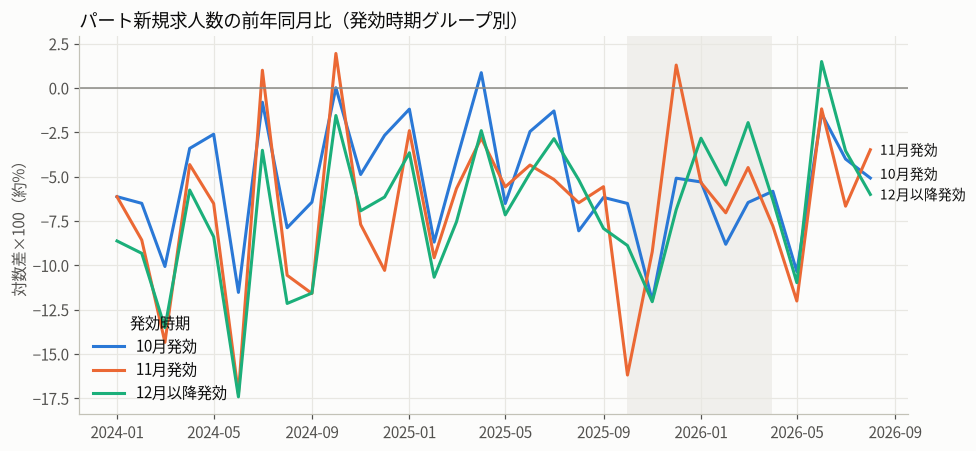

In [5]:
TREND_END = END

trend = (panel[(panel["month"] >= pd.Period("2024-01", "M")) & (panel["month"] <= TREND_END)]
         .groupby(["month", "group"], observed=True)["yoy"].mean().unstack())
fig, ax = plt.subplots(figsize=(9, 4.2))
x = trend.index.to_timestamp()
for g in GROUP_ORDER:
    ax.plot(x, trend[g], color=COLORS[g], label=g)
# 右端のラベル：重ならないよう下から順に最小間隔をあける
ends = trend.iloc[-1].sort_values()
gap = 0.06 * (trend.max().max() - trend.min().min())
label_y = []
for v in ends:
    label_y.append(max(v, label_y[-1] + gap) if label_y else v)
for g, y in zip(ends.index, label_y):
    ax.text(x[-1] + pd.Timedelta(days=12), y, g, va="center", fontsize=9, color="#0b0b0b")
ax.axhline(0, color="#8a8984", lw=1)

ax.axvspan(pd.Timestamp("2025-10-01"), pd.Timestamp("2026-03-31"), color="#e8e7e2", alpha=0.6, lw=0)
ax.set_title("パート新規求人数の前年同月比（発効時期グループ別）", loc="left")
ax.set_ylabel("対数差×100（約%）")
ax.legend(title="発効時期", frameon=False, loc="lower left")
fig.tight_layout()

In [6]:
trend.loc["2025-04":].round(2)

group,10月発効,11月発効,12月以降発効
month,,,
2025-04,0.86,-2.83,-2.41
2025-05,-6.52,-5.58,-7.16
2025-06,-2.46,-4.35,-4.80
2025-07,-1.30,-5.17,-2.86
2025-08,-8.06,-6.48,-5.18
2025-09,-6.18,-5.57,-7.93
2025-10,-6.52,-16.19,-8.89
2025-11,-11.99,-9.24,-12.06
2025-12,-5.09,1.29,-6.87


## 2. 発表の案：2025年11月、10月発効 vs 12月以降発効

2025年11月の時点で、10月発効の20県には新しい最低賃金が適用され、12月以降発効の14県にはまだ適用されていない（11月発効の13県は除く）。

In [7]:
def two_group_diff(df):
    a = df.loc[df["group"] == "10月発効", "yoy"]
    b = df.loc[df["group"] == "12月以降発効", "yoy"]
    return pd.Series({"10月発効_平均": a.mean(), "12月以降_平均": b.mean(),
                      "差（10月−12月以降）": a.mean() - b.mean(),
                      "10月発効_SD": a.std(), "12月以降_SD": b.std()})

diff = (panel[panel["month"] >= pd.Period("2025-01", "M")]
        .groupby("month").apply(two_group_diff, include_groups=False))
diff

,10月発効_平均,12月以降_平均,差（10月−12月以降）,10月発効_SD,12月以降_SD
month,,,,,
2025-01,-1.20,-3.66,2.46,7.00,6.16
2025-02,-8.70,-10.68,1.98,7.83,7.10
2025-03,-4.08,-7.55,3.46,5.87,6.99
2025-04,0.86,-2.41,3.27,7.25,7.83
2025-05,-6.52,-7.16,0.64,9.16,5.92
2025-06,-2.46,-4.80,2.34,9.61,8.64
2025-07,-1.30,-2.86,1.56,6.06,6.25
2025-08,-8.06,-5.18,-2.88,5.75,6.11
2025-09,-6.18,-7.93,1.75,6.83,6.26


In [8]:
pre_gap = diff.loc["2025-04":"2025-09", "差（10月−12月以降）"]
nov_gap = diff.loc[pd.Period("2025-11", "M"), "差（10月−12月以降）"]
print(f"改定前（2025年4〜9月）のグループ間の差：平均 {pre_gap.mean():.2f}、範囲 {pre_gap.min():.2f} 〜 {pre_gap.max():.2f}")
print(f"2025年11月のグループ間の差：{nov_gap:.2f}")

改定前（2025年4〜9月）のグループ間の差：平均 1.11、範囲 -2.88 〜 3.27
2025年11月のグループ間の差：0.07


**メモ（試行時点）：**

- 2025年11月の前年同月比は両グループとも約−12で、差はほぼ0。改定前のグループ間の差の変動の範囲内にある。
- 2026年1〜3月には差がマイナス（約−2.5〜−4.5）になるが、12月以降発効グループでも順次発効しており、県数が少なく標準偏差も大きい（1〜2月は約11）。
- 11月発効グループの2025年10月の前年同月比は−16.19で、他より明らかに低い。原因は未確認。
- 2024年度の改定はほぼすべて2024年10月に発効したため、2025年11月の前年同月比は「2024年度改定後」の月との比較になる。

## 3. 引上げ率と前年同月比（2025年11月）

,"グループ内相関（引上げ率, 前年同月比）"
group,
10月発効,-0.11
11月発効,-0.23
12月以降発効,-0.22


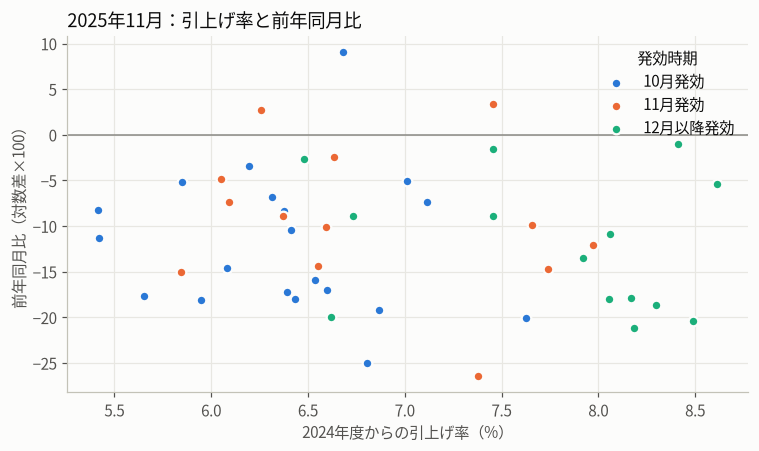

In [9]:
nov = panel[panel["month"] == pd.Period("2025-11", "M")].set_index("pref")
fig, ax = plt.subplots(figsize=(7, 4.2))
for g in GROUP_ORDER:
    s = nov[nov["group"] == g]
    ax.scatter(s["raise_pct"], s["yoy"], s=40, color=COLORS[g], edgecolor="#fcfcfb",
               linewidth=1.5, label=g, zorder=3)
ax.axhline(0, color="#8a8984", lw=1)
ax.set_title("2025年11月：引上げ率と前年同月比", loc="left")
ax.set_xlabel("2024年度からの引上げ率（%）")
ax.set_ylabel("前年同月比（対数差×100）")
ax.legend(title="発効時期", frameon=False)
fig.tight_layout()

nov.groupby("group", observed=True)[["raise_pct", "yoy"]].corr().xs("yoy", level=1)[["raise_pct"]] \
   .rename(columns={"raise_pct": "グループ内相関（引上げ率, 前年同月比）"})

**メモ（試行時点）：** 各グループ内の相関は弱い負（約−0.1〜−0.2）。各グループ13〜20県しかない。

## 4. 整形したパネルの保存

回帰分析に使う場合に備え、長い形式（long format）のCSVとして保存する。Colabでは `/content/data/processed/` に保存され、ランタイム終了で消える。

列：`month`、`pref`、`openings`（パート新規求人数）、`log_open`、`yoy`（前年同月比、対数差×100）、`group`（発効時期グループ）、`mw_2025`、`raise_yen`、`raise_pct`、`effective`。

In [10]:
OUT.mkdir(parents=True, exist_ok=True)
save = panel.assign(month=panel["month"].astype(str),
                    effective=panel["effective"].dt.strftime("%Y-%m-%d"))
save.to_csv(OUT / "part_new_openings_panel.csv", index=False, encoding="utf-8-sig")
print("保存：data/processed/part_new_openings_panel.csv", save.shape)

保存：data/processed/part_new_openings_panel.csv (2068, 10)
